In [ ]:
import importlib
import nn
importlib.reload(nn)
from nn import NeuralNetwork, train
from data import load_mnist
from data import one_hot
import importlib
import plotting
importlib.reload(plotting)
from plotting import plot_heatmap
from optimizers import Adam
from metrics import accuracy, confusion_matrix
import matplotlib.pyplot as plt

In [25]:
(x_train, y_train), (x_val, y_val), (x_test, y_test) = load_mnist(path="../data/mnist.npz",seed=2026)
y_train_oh, y_val_oh = one_hot(y_train), one_hot(y_val) 

In [26]:
model = NeuralNetwork(layer_sizes=[784, 100, 10], activations=["relu", "softmax"], cost="cross_entropy", seed=2026)
optimizer = Adam(learning_rate=0.001)
history=train(model, optimizer, X=x_train, y=y_train_oh, epochs=10, batch_size=128, seed=2026, X_val=x_val, y_val=y_val_oh)

In [28]:
y_pred = model.predict(x_val)
print(f"Validation accuracy: {accuracy(y_val, y_pred):.4f}")
print(f"Cross entropy start: {history['train'][0]:.4f}")
print(f"Cross entropy end: {history['train'][-1]:.4f}")


Validation accuracy: 0.9746
Cross entropy start: 0.2270
Cross entropy end: 0.0383


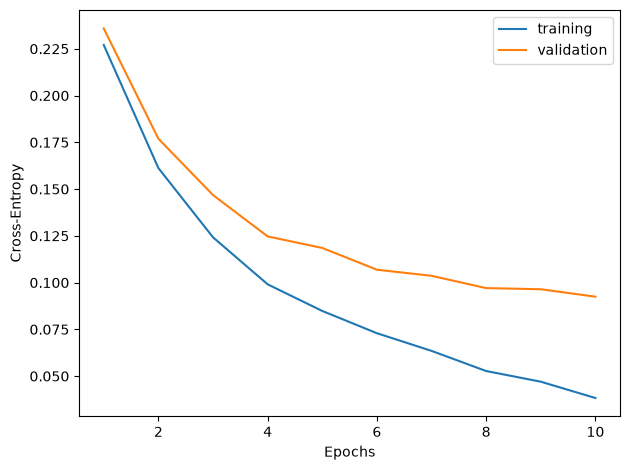

In [32]:
epochs = range(1, len(history["train"])+ 1)
plt.plot(epochs, history['train'], label = 'training')
plt.plot(epochs, history['val'], label = 'validation')
plt.xlabel("Epochs");plt.ylabel('Cross-Entropy');plt.legend();plt.tight_layout();plt.show()

